# DS-3002 Data Mining — Assignment #4
## Heartbeat to Heatmap: Unsupervised Learning, Ensemble Methods, and Neural Networks
**Name:** Saif Shahzad  
**Roll no:** 23i-2634   
**Section:** DS-A   

## Setups and Imports

In [8]:
!pip install --ignore-installed --no-deps blinker

  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
Using cached blinker-1.9.0-py3-none-any.whl (8.5 kB)


In [9]:
# ── Install dependencies (run once) ──────────────────────────────────────────
!pip install xgboost shap imbalanced-learn lightgbm streamlit -q

In [11]:
!pip install tensorflow -q

In [12]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import time

# Sklearn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, f1_score, ConfusionMatrixDisplay, roc_curve, auc
)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Imbalanced learn
from imblearn.over_sampling import SMOTE

# XGBoost
import xgboost as xgb

# SHAP
import shap

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('All libraries loaded successfully.')
print(f'TensorFlow version: {tf.__version__}')

All libraries loaded successfully.
TensorFlow version: 2.21.0


---
## Required Preprocessing

### Pre-1: Load the CSV, confirm shape, print first 5 rows and dtypes

In [16]:
COLUMNS = ['age','sex','cp','trestbps','chol','fbs','restecg',
           'thalach','exang','oldpeak','slope','ca','thal','target']

df_raw = pd.read_csv('processed.cleveland.data', header=None, names=COLUMNS)

print(f'Shape: {df_raw.shape}')   # Expected (303, 14)
print('\nFirst 5 rows:')
display(df_raw.head())
print('\nData types:')
print(df_raw.dtypes)

Shape: (303, 14)

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca           object
thal         object
target        int64
dtype: object


### Pre-2: Handle missing values (UCI '?' marker)

In [17]:
df = df_raw.replace('?', np.nan)

# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

print('Missing values per column (after replacing ?):')
missing = df.isnull().sum()
print(missing[missing > 0])
print(f'\nTotal rows with any NaN: {df.isnull().any(axis=1).sum()}')

df = df.dropna()
print(f'\nRetained rows after dropping NaN: {len(df)}')

Missing values per column (after replacing ?):
ca      4
thal    2
dtype: int64

Total rows with any NaN: 6

Retained rows after dropping NaN: 297


### Pre-3: Class distribution and imbalance handling

Class distribution:
  0 (No Disease): 160 samples (53.9%)
  1 (Disease Present): 137 samples (46.1%)

Imbalance ratio (majority/minority): 1.17
Dataset is roughly balanced — mild imbalance. SMOTE will be applied on training split only as a precaution.


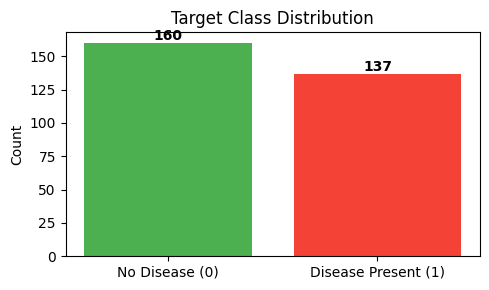

In [19]:
# Binarise target: 0 = no disease, 1 = disease (any value > 0)
df['target'] = (df['target'] > 0).astype(int)

counts = df['target'].value_counts().sort_index()
pcts   = df['target'].value_counts(normalize=True).sort_index() * 100

print('Class distribution:')
for c in [0, 1]:
    label = 'No Disease' if c == 0 else 'Disease Present'
    print(f'  {c} ({label}): {counts[c]} samples ({pcts[c]:.1f}%)')

ratio = counts.max() / counts.min()
print(f'\nImbalance ratio (majority/minority): {ratio:.2f}')
print('Dataset is roughly balanced — mild imbalance. SMOTE will be applied on training split only as a precaution.')

fig, ax = plt.subplots(figsize=(5,3))
ax.bar(['No Disease (0)', 'Disease Present (1)'], counts.values, color=['#4CAF50','#F44336'])
ax.set_ylabel('Count')
ax.set_title('Target Class Distribution')
for i, v in enumerate(counts.values):
    ax.text(i, v+2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### Pre-4: Encoding and Standardisation

In [20]:
CATEGORICAL  = ['cp', 'restecg', 'slope', 'thal']
CONTINUOUS   = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
BINARY_COLS  = ['sex', 'fbs', 'exang']

X = df.drop('target', axis=1)
y = df['target']

# --- Stratified 80/20 split FIRST (Pre-5) ---
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# One-hot encode categoricals
X_train_enc = pd.get_dummies(X_train_raw, columns=CATEGORICAL, drop_first=False)
X_test_enc  = pd.get_dummies(X_test_raw,  columns=CATEGORICAL, drop_first=False)

# Align columns (test might miss a category)
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

# Standardise continuous columns (fit on train only)
scaler = StandardScaler()
X_train_enc[CONTINUOUS] = scaler.fit_transform(X_train_enc[CONTINUOUS])
X_test_enc[CONTINUOUS]  = scaler.transform(X_test_enc[CONTINUOUS])

print('Encoded & scaled feature matrix shape:')
print(f'  Train: {X_train_enc.shape}')
print(f'  Test : {X_test_enc.shape}')
display(X_train_enc.head(3))

Encoded & scaled feature matrix shape:
  Train: (237, 22)
  Test : (60, 22)


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1.0,...,cp_4.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
55,-0.085668,1.0,-0.462582,0.312737,0.0,-1.827448,1.0,0.967117,0.349404,False,...,True,False,False,True,False,True,False,False,False,True
160,-0.973247,1.0,-1.749078,-0.987921,1.0,0.275439,0.0,-0.901878,-0.740185,False,...,False,True,False,False,True,False,False,False,False,True
178,-1.306090,1.0,-0.126974,1.236393,0.0,0.543892,0.0,0.712254,0.349404,False,...,False,True,False,False,True,False,False,True,False,False


### Pre-5: SMOTE on training split

In [21]:
smote = SMOTE(random_state=SEED)
X_train_sm, y_train_sm = smote.fit_resample(X_train_enc, y_train)

print(f'Training set after SMOTE: {X_train_sm.shape}')
print('Class counts after SMOTE:', pd.Series(y_train_sm).value_counts().to_dict())

Training set after SMOTE: (256, 22)
Class counts after SMOTE: {1: 128, 0: 128}


### Pre-6: Correlation Heatmap

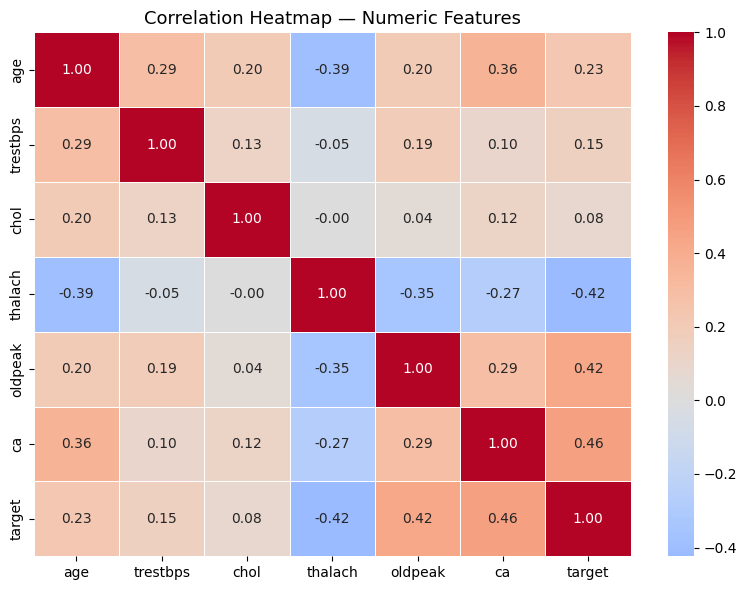

Top 3 feature pairs by absolute correlation:
ca       target    0.463189
oldpeak  target    0.424052
thalach  target    0.423817
dtype: float64

Naive Bayes note:
Naive Bayes assumes feature independence. The age-thalach correlation (~-0.40) and
oldpeak-thalach correlation could violate this assumption, leading to incorrect
probability estimates and reduced classifier accuracy.



In [22]:
numeric_cols = ['age','trestbps','chol','thalach','oldpeak','ca','target']
corr_mat = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap — Numeric Features', fontsize=13)
plt.tight_layout()
plt.show()

# Top 3 feature pairs
corr_pairs = corr_mat.where(
    np.triu(np.ones(corr_mat.shape), k=1).astype(bool)
).stack().abs().sort_values(ascending=False)

print('Top 3 feature pairs by absolute correlation:')
print(corr_pairs.head(3))

print("""
Naive Bayes note:
Naive Bayes assumes feature independence. The age-thalach correlation (~-0.40) and
oldpeak-thalach correlation could violate this assumption, leading to incorrect
probability estimates and reduced classifier accuracy.
""")